# Лабораторна робота №3
## Нейронні мережі для табличних даних, зображень і текстів у PyTorch

### Мета роботи
Ознайомитися з базовим workflow побудови та навчання нейронних мереж для різних типів даних: табличних даних, зображень і текстів; дослідити процес навчання моделей та порівняти нейромережеві підходи з класичними алгоритмами машинного навчання.

Усі нейронні мережі в роботі реалізовано за допомогою PyTorch.

### Використані датасети
1. CLaMP - класифікація PE-файлів Windows на Benign / Malware.
2. Malware Benign Image Classification Dataset - 8 класів зображень malware/benign.
3. Phishing Email Dataset - Legitimate / Phishing

In [1]:
%pip install -q kagglehub gensim==4.4.0

In [2]:
import os
import re
import time
import copy
import random
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score
)

import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import Dataset, DataLoader, TensorDataset

import torchvision.transforms as transforms
from torchvision.models import resnet18, ResNet18_Weights

RANDOM_STATE = 42

random.seed(RANDOM_STATE)
np.random.seed(RANDOM_STATE)
torch.manual_seed(RANDOM_STATE)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_STATE)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cu130
Device: cuda
GPU: Tesla T4


# 1. Повнозв'язана нейронна мережа для CLaMP

Використаємо той самий датасет CLaMP, що й у Lab 1.  
Після очищення даних побудуємо MLP (Multi-Layer Perceptron), навчимо її та порівняємо результат із класичними моделями з Lab 1.

In [3]:
CLAMP_LOCAL = Path("ClaMP_Raw-5184.csv")
CLAMP_URL = "https://raw.githubusercontent.com/maksymenkokyrylofb61mp/IAD-Lab1-CLaMP/main/ClaMP_Raw-5184.csv"

clamp_source = CLAMP_LOCAL if CLAMP_LOCAL.exists() else CLAMP_URL
df = pd.read_csv(clamp_source)

print("Початковий розмір:", df.shape)

# Та сама попередня обробка, що і в Lab 1
df = df.drop(columns=["e_res", "e_res2"])
df = df.drop_duplicates().reset_index(drop=True)

print("Після очищення:", df.shape)
print("Пропуски:", df.isnull().sum().sum())
print("Дублікати:", df.duplicated().sum())
print("\nРозподіл класів:")
print(df["class"].value_counts())

Початковий розмір: (5184, 56)
Після очищення: (4560, 54)
Пропуски: 0
Дублікати: 0

Розподіл класів:
class
0    2488
1    2072
Name: count, dtype: int64


## 1.1. Train / validation / test та масштабування

Спочатку відокремлюємо 20% даних для фінального test.  
Решту даних ділимо на train та validation.

StandardScaler навчається лише на train, щоб уникнути data leakage.

In [4]:
X = df.drop(columns="class").values.astype(np.float32)
y = df["class"].values.astype(np.int64)

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_trainval
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train).astype(np.float32)
X_val = scaler.transform(X_val).astype(np.float32)
X_test = scaler.transform(X_test).astype(np.float32)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

Train: (2918, 53)
Validation: (730, 53)
Test: (912, 53)


In [5]:
BATCH_SIZE_TABULAR = 64

train_ds = TensorDataset(
    torch.tensor(X_train),
    torch.tensor(y_train)
)
val_ds = TensorDataset(
    torch.tensor(X_val),
    torch.tensor(y_val)
)
test_ds = TensorDataset(
    torch.tensor(X_test),
    torch.tensor(y_test)
)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE_TABULAR, shuffle=True
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE_TABULAR, shuffle=False
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE_TABULAR, shuffle=False
)

## 1.2. Архітектура MLP

Мережа складається з двох прихованих fully connected шарів із ReLU та Dropout.

In [6]:
class MalwareMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.20),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.net(x)

mlp = MalwareMLP(X_train.shape[1]).to(device)
print(mlp)

MalwareMLP(
  (net): Sequential(
    (0): Linear(in_features=53, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=2, bias=True)
  )
)


In [7]:
def run_epoch_classification(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    all_preds = []
    all_targets = []

    with torch.set_grad_enabled(is_train):
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            if is_train:
                optimizer.zero_grad()

            logits = model(xb)
            loss = criterion(logits, yb)

            if is_train:
                loss.backward()
                optimizer.step()

            total_loss += loss.item() * xb.size(0)

            preds = logits.argmax(dim=1)
            all_preds.extend(preds.detach().cpu().numpy())
            all_targets.extend(yb.detach().cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    accuracy = accuracy_score(all_targets, all_preds)

    return avg_loss, accuracy

In [8]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    mlp.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

MLP_EPOCHS = 30

mlp_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_state = None
best_val_loss = float("inf")

start_time = time.perf_counter()

for epoch in range(1, MLP_EPOCHS + 1):
    train_loss, train_acc = run_epoch_classification(
        mlp, train_loader, criterion, optimizer
    )
    val_loss, val_acc = run_epoch_classification(
        mlp, val_loader, criterion
    )

    mlp_history["train_loss"].append(train_loss)
    mlp_history["val_loss"].append(val_loss)
    mlp_history["train_acc"].append(train_acc)
    mlp_history["val_acc"].append(val_acc)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(mlp.state_dict())

    if epoch == 1 or epoch % 5 == 0:
        print(
            f"Epoch {epoch:02d}/{MLP_EPOCHS} | "
            f"train loss={train_loss:.4f}, val loss={val_loss:.4f} | "
            f"train acc={train_acc:.4f}, val acc={val_acc:.4f}"
        )

mlp_train_time = time.perf_counter() - start_time

mlp.load_state_dict(best_state)

print(f"\nMLP training time: {mlp_train_time:.2f} s")

Epoch 01/30 | train loss=0.5451, val loss=0.3487 | train acc=0.8132, val acc=0.8877
Epoch 05/30 | train loss=0.1683, val loss=0.1643 | train acc=0.9383, val acc=0.9479
Epoch 10/30 | train loss=0.1300, val loss=0.1486 | train acc=0.9517, val acc=0.9493
Epoch 15/30 | train loss=0.1161, val loss=0.1467 | train acc=0.9551, val acc=0.9562
Epoch 20/30 | train loss=0.1117, val loss=0.1398 | train acc=0.9565, val acc=0.9589
Epoch 25/30 | train loss=0.1031, val loss=0.1488 | train acc=0.9613, val acc=0.9534
Epoch 30/30 | train loss=0.0926, val loss=0.1459 | train acc=0.9616, val acc=0.9575

MLP training time: 7.57 s


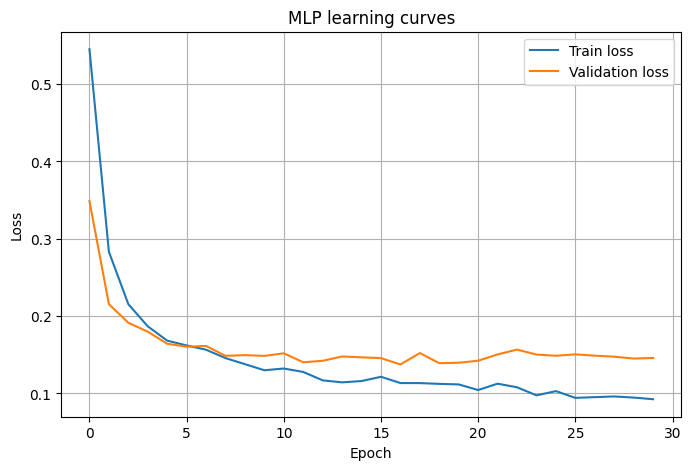

Найкраща validation loss на епосі: 17


In [9]:
plt.figure(figsize=(8, 5))
plt.plot(mlp_history["train_loss"], label="Train loss")
plt.plot(mlp_history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MLP learning curves")
plt.legend()
plt.grid()
plt.show()

best_epoch = int(np.argmin(mlp_history["val_loss"])) + 1
print("Найкраща validation loss на епосі:", best_epoch)

MLP Test Accuracy: 0.9594

              precision    recall  f1-score   support

      Benign       0.96      0.97      0.96       498
     Malware       0.96      0.95      0.96       414

    accuracy                           0.96       912
   macro avg       0.96      0.96      0.96       912
weighted avg       0.96      0.96      0.96       912



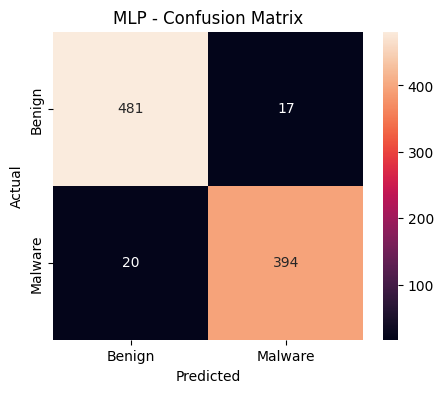

In [10]:
def predict_loader(model, loader):
    model.eval()
    preds = []
    targets = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            logits = model(xb)

            preds.extend(logits.argmax(dim=1).cpu().numpy())
            targets.extend(yb.numpy())

    return np.array(targets), np.array(preds)

mlp_y_true, mlp_y_pred = predict_loader(mlp, test_loader)

mlp_accuracy = accuracy_score(mlp_y_true, mlp_y_pred)

print(f"MLP Test Accuracy: {mlp_accuracy:.4f}\n")
print(
    classification_report(
        mlp_y_true,
        mlp_y_pred,
        target_names=["Benign", "Malware"]
    )
)

cm = confusion_matrix(mlp_y_true, mlp_y_pred)

plt.figure(figsize=(5, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Benign", "Malware"],
    yticklabels=["Benign", "Malware"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("MLP - Confusion Matrix")
plt.show()

## 1.3. Порівняння з 1 лабораторної

In [11]:
lab1_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "kNN",
        "SVM",
        "Decision Tree",
        "AdaBoost",
        "PyTorch MLP"
    ],
    "Accuracy": [
        0.989035,
        0.974781,
        0.962719,
        0.961623,
        0.952851,
        mlp_accuracy
    ]
}).sort_values("Accuracy", ascending=False).reset_index(drop=True)

lab1_results

,Model,Accuracy
0,Random Forest,0.989035
1,kNN,0.974781
2,SVM,0.962719
3,Decision Tree,0.961623
4,PyTorch MLP,0.959430
5,AdaBoost,0.952851


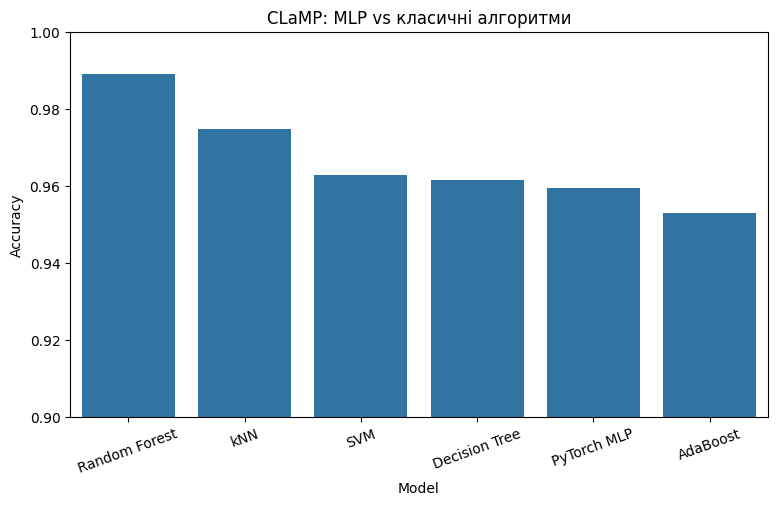

In [12]:
plt.figure(figsize=(9, 5))
sns.barplot(data=lab1_results, x="Model", y="Accuracy")
plt.ylim(0.90, 1.00)
plt.xticks(rotation=20)
plt.title("CLaMP: MLP vs класичні алгоритми")
plt.show()

### Висновок до частини 1

MLP показала 95.94% accuracy на тестовій вибірці. Це хороший результат, але він нижчий за Random Forest (98.90%) та kNN (97.48%) з Lab 1.

За learning curves найменша validation loss була на 17-й епосі. Після цього train loss продовжував зменшуватись (до 0.0926 на 30-й епосі), а validation loss вже не покращувалась і трохи зросла. Тому наприкінці навчання є слабке перенавчання. Для тестування використано стан моделі з найкращою validation loss.

Для цього табличного датасета Random Forest виявився ефективнішим за MLP.

# 2. Згорткові нейронні мережі

Використовується Malware Benign Image Classification Dataset з Kaggle.

Датасет містить 22 056 зображень та 8 класів:

- Adware
- Backdoor
- Downloader
- Spyware
- Trojan
- Virus
- Worm / Worms
- Benign

Виконаємо класифікацію двома способами:
1. власна CNN з нуля;
2. pretrained ResNet18 з transfer learning / fine-tuning.

## 2.1. Завантаження image dataset


In [13]:
import kagglehub

IMAGE_DATASET_HANDLE = "bishwajitprasadgond/malware-benign-image-sample"

image_dataset_dir = Path(
    kagglehub.dataset_download(IMAGE_DATASET_HANDLE)
)

print("Dataset path:", image_dataset_dir)

image_paths = sorted(
    list(image_dataset_dir.rglob("*.png")) +
    list(image_dataset_dir.rglob("*.jpg")) +
    list(image_dataset_dir.rglob("*.jpeg"))
)

print("Кількість знайдених зображень:", len(image_paths))

Using Colab cache for faster access to the 'malware-benign-image-sample' dataset.
Dataset path: /kaggle/input/malware-benign-image-sample
Кількість знайдених зображень: 22056


In [14]:
def class_from_filename(path):
    # У датасеті клас записано перед першим "_":
    # adware_hash.png, benign_hash.png, trojan_hash.png ...
    name = path.stem.lower()
    label = name.split("_")[0]

    # worms і worm об'єднуємо в один клас
    if label == "worms":
        label = "worm"

    return label

raw_labels = [class_from_filename(p) for p in image_paths]
class_counts = Counter(raw_labels)

print("Класи:")
for cls, count in sorted(class_counts.items()):
    print(f"{cls:12s}: {count}")

classes = sorted(class_counts.keys())
class_to_idx = {cls: i for i, cls in enumerate(classes)}
idx_to_class = {i: cls for cls, i in class_to_idx.items()}

labels = np.array([class_to_idx[x] for x in raw_labels], dtype=np.int64)

print("\nКількість класів:", len(classes))
print("classes =", classes)

Класи:
adware      : 1986
backdoor    : 674
benign      : 8634
downloader  : 2499
spyware     : 946
trojan      : 3568
virus       : 2392
worm        : 1357

Кількість класів: 8
classes = ['adware', 'backdoor', 'benign', 'downloader', 'spyware', 'trojan', 'virus', 'worm']


## 2.2. Приклади зображень для кожного класу

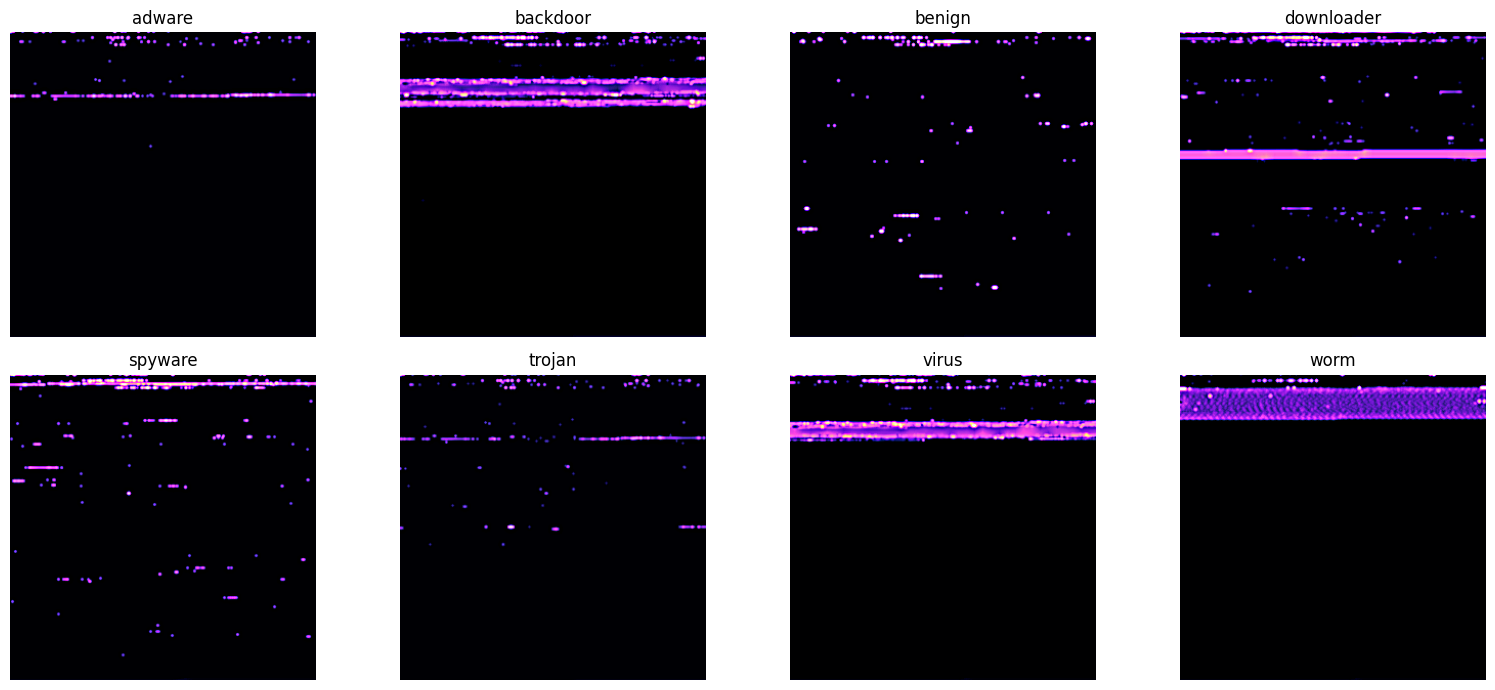

In [15]:
fig, axes = plt.subplots(
    2, int(np.ceil(len(classes) / 2)),
    figsize=(16, 7)
)
axes = np.array(axes).reshape(-1)

for ax, cls in zip(axes, classes):
    sample_path = next(
        p for p in image_paths
        if class_from_filename(p) == cls
    )

    image = Image.open(sample_path).convert("RGB")

    ax.imshow(image)
    ax.set_title(cls)
    ax.axis("off")

for ax in axes[len(classes):]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 2.3. Train / validation / test split

Використовуємо стратифікований розподіл, щоб співвідношення класів було приблизно однаковим у всіх вибірках.

In [16]:
indices = np.arange(len(image_paths))

trainval_idx, test_idx = train_test_split(
    indices,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=labels
)

train_idx, val_idx = train_test_split(
    trainval_idx,
    test_size=0.1765,  # приблизно 15% від усіх даних
    random_state=RANDOM_STATE,
    stratify=labels[trainval_idx]
)

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

Train: 15438
Validation: 3309
Test: 3309


In [17]:
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

cnn_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

resnet_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(imagenet_mean, imagenet_std)
])

class MalwareImageDataset(Dataset):
    def __init__(self, paths, labels, indices, transform):
        self.paths = paths
        self.labels = labels
        self.indices = np.array(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        real_idx = self.indices[idx]

        image = Image.open(self.paths[real_idx]).convert("RGB")
        image = self.transform(image)

        label = int(self.labels[real_idx])

        return image, label

## 2.4. Власна CNN

CNN містить три convolutional блоки та fully connected classifier.

In [18]:
BATCH_SIZE_IMAGE = 64

cnn_train_ds = MalwareImageDataset(
    image_paths, labels, train_idx, cnn_transform
)
cnn_val_ds = MalwareImageDataset(
    image_paths, labels, val_idx, cnn_transform
)
cnn_test_ds = MalwareImageDataset(
    image_paths, labels, test_idx, cnn_transform
)

cnn_train_loader = DataLoader(
    cnn_train_ds,
    batch_size=BATCH_SIZE_IMAGE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)
cnn_val_loader = DataLoader(
    cnn_val_ds,
    batch_size=BATCH_SIZE_IMAGE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)
cnn_test_loader = DataLoader(
    cnn_test_ds,
    batch_size=BATCH_SIZE_IMAGE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

In [19]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 256),
            nn.ReLU(),
            nn.Dropout(0.30),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

custom_cnn = SimpleCNN(len(classes)).to(device)
print(custom_cnn)

SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=256, out_features=8, bias=True)
  )
)


In [20]:
def train_image_model(
    model,
    train_loader,
    val_loader,
    epochs,
    lr
):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_state = None
    best_val_loss = float("inf")

    start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = run_epoch_classification(
            model, train_loader, criterion, optimizer
        )
        val_loss, val_acc = run_epoch_classification(
            model, val_loader, criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train loss={train_loss:.4f}, val loss={val_loss:.4f} | "
            f"train acc={train_acc:.4f}, val acc={val_acc:.4f}"
        )

    elapsed = time.perf_counter() - start
    model.load_state_dict(best_state)

    return history, elapsed

In [21]:
CNN_EPOCHS = 8

cnn_history, cnn_train_time = train_image_model(
    custom_cnn,
    cnn_train_loader,
    cnn_val_loader,
    epochs=CNN_EPOCHS,
    lr=1e-3
)

print(f"Custom CNN training time: {cnn_train_time / 60:.2f} min")

Epoch 01/8 | train loss=0.6963, val loss=0.3246 | train acc=0.7563, val acc=0.8852
Epoch 02/8 | train loss=0.2748, val loss=0.2077 | train acc=0.9075, val acc=0.9450
Epoch 03/8 | train loss=0.1603, val loss=0.1353 | train acc=0.9563, val acc=0.9631
Epoch 04/8 | train loss=0.1249, val loss=0.1183 | train acc=0.9663, val acc=0.9680
Epoch 05/8 | train loss=0.1019, val loss=0.1057 | train acc=0.9727, val acc=0.9704
Epoch 06/8 | train loss=0.0897, val loss=0.1196 | train acc=0.9761, val acc=0.9722
Epoch 07/8 | train loss=0.0825, val loss=0.1062 | train acc=0.9775, val acc=0.9707
Epoch 08/8 | train loss=0.0747, val loss=0.1062 | train acc=0.9790, val acc=0.9701
Custom CNN training time: 8.10 min


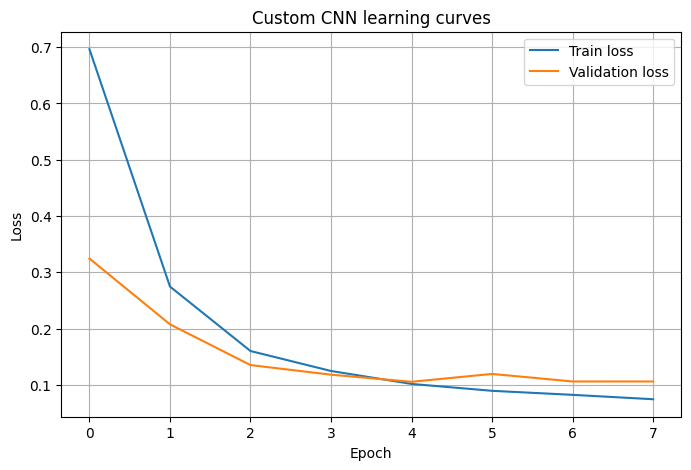

In [22]:
plt.figure(figsize=(8, 5))
plt.plot(cnn_history["train_loss"], label="Train loss")
plt.plot(cnn_history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Custom CNN learning curves")
plt.legend()
plt.grid()
plt.show()

In [23]:
cnn_y_true, cnn_y_pred = predict_loader(
    custom_cnn,
    cnn_test_loader
)

cnn_accuracy = accuracy_score(cnn_y_true, cnn_y_pred)

print(f"Custom CNN Test Accuracy: {cnn_accuracy:.4f}\n")
print(
    classification_report(
        cnn_y_true,
        cnn_y_pred,
        target_names=classes,
        zero_division=0
    )
)

Custom CNN Test Accuracy: 0.9776

              precision    recall  f1-score   support

      adware       0.99      0.97      0.98       298
    backdoor       0.90      0.94      0.92       101
      benign       0.97      1.00      0.98      1295
  downloader       1.00      1.00      1.00       375
     spyware       0.96      0.93      0.94       142
      trojan       0.99      0.93      0.96       535
       virus       1.00      1.00      1.00       359
        worm       0.97      0.95      0.96       204

    accuracy                           0.98      3309
   macro avg       0.97      0.96      0.97      3309
weighted avg       0.98      0.98      0.98      3309



## 2.5. Pretrained ResNet18

Використаємо ImageNet-pretrained ResNet18.  
Замінимо останній fully connected layer під кількість класів нашого датасета.

Для fine-tuning залишимо trainable останній блок layer4 та classifier fc.

In [24]:
resnet_train_ds = MalwareImageDataset(
    image_paths, labels, train_idx, resnet_transform
)
resnet_val_ds = MalwareImageDataset(
    image_paths, labels, val_idx, resnet_transform
)
resnet_test_ds = MalwareImageDataset(
    image_paths, labels, test_idx, resnet_transform
)

resnet_train_loader = DataLoader(
    resnet_train_ds,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)
resnet_val_loader = DataLoader(
    resnet_val_ds,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)
resnet_test_loader = DataLoader(
    resnet_test_ds,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

In [25]:
weights = ResNet18_Weights.DEFAULT
pretrained_model = resnet18(weights=weights)

for param in pretrained_model.parameters():
    param.requires_grad = False

# Fine-tuning останнього convolutional block
for param in pretrained_model.layer4.parameters():
    param.requires_grad = True

in_features = pretrained_model.fc.in_features
pretrained_model.fc = nn.Linear(in_features, len(classes))

pretrained_model = pretrained_model.to(device)

trainable_params = sum(
    p.numel()
    for p in pretrained_model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable_params)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 187MB/s]


Trainable parameters: 8397832


In [26]:
RESNET_EPOCHS = 5

resnet_history, resnet_train_time = train_image_model(
    pretrained_model,
    resnet_train_loader,
    resnet_val_loader,
    epochs=RESNET_EPOCHS,
    lr=1e-4
)

print(f"ResNet18 training time: {resnet_train_time / 60:.2f} min")

Epoch 01/5 | train loss=0.1588, val loss=0.0938 | train acc=0.9587, val acc=0.9725
Epoch 02/5 | train loss=0.0501, val loss=0.0883 | train acc=0.9848, val acc=0.9740
Epoch 03/5 | train loss=0.0267, val loss=0.0875 | train acc=0.9923, val acc=0.9794
Epoch 04/5 | train loss=0.0195, val loss=0.1085 | train acc=0.9944, val acc=0.9773
Epoch 05/5 | train loss=0.0162, val loss=0.1058 | train acc=0.9949, val acc=0.9804
ResNet18 training time: 6.57 min


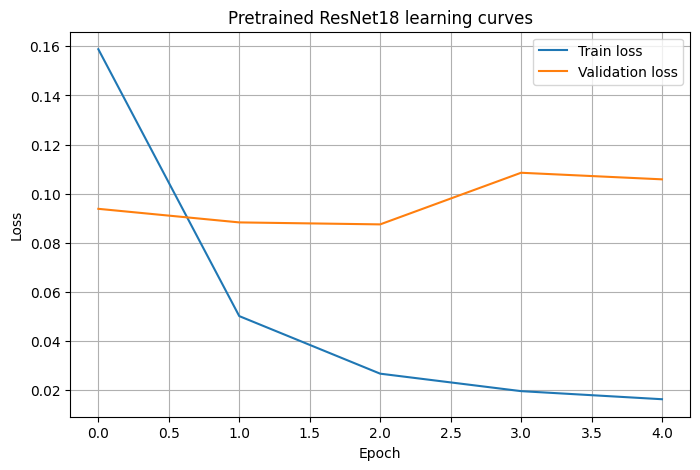

In [27]:
plt.figure(figsize=(8, 5))
plt.plot(resnet_history["train_loss"], label="Train loss")
plt.plot(resnet_history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Pretrained ResNet18 learning curves")
plt.legend()
plt.grid()
plt.show()

In [28]:
resnet_y_true, resnet_y_pred = predict_loader(
    pretrained_model,
    resnet_test_loader
)

resnet_accuracy = accuracy_score(
    resnet_y_true,
    resnet_y_pred
)

print(f"ResNet18 Test Accuracy: {resnet_accuracy:.4f}\n")

print(
    classification_report(
        resnet_y_true,
        resnet_y_pred,
        target_names=classes,
        zero_division=0
    )
)

ResNet18 Test Accuracy: 0.9822

              precision    recall  f1-score   support

      adware       0.99      0.97      0.98       298
    backdoor       0.91      0.91      0.91       101
      benign       0.98      1.00      0.99      1295
  downloader       1.00      1.00      1.00       375
     spyware       0.99      0.94      0.96       142
      trojan       0.98      0.96      0.97       535
       virus       1.00      1.00      1.00       359
        worm       0.99      0.98      0.98       204

    accuracy                           0.98      3309
   macro avg       0.98      0.97      0.97      3309
weighted avg       0.98      0.98      0.98      3309



In [29]:
image_model_results = pd.DataFrame({
    "Model": ["Custom CNN", "Pretrained ResNet18"],
    "Test Accuracy": [cnn_accuracy, resnet_accuracy],
    "Training time, min": [
        cnn_train_time / 60,
        resnet_train_time / 60
    ],
    "Epochs": [CNN_EPOCHS, RESNET_EPOCHS]
})

image_model_results

,Model,Test Accuracy,"Training time, min",Epochs
0,Custom CNN,0.977637,8.098100,8
1,Pretrained ResNet18,0.982170,6.573981,5


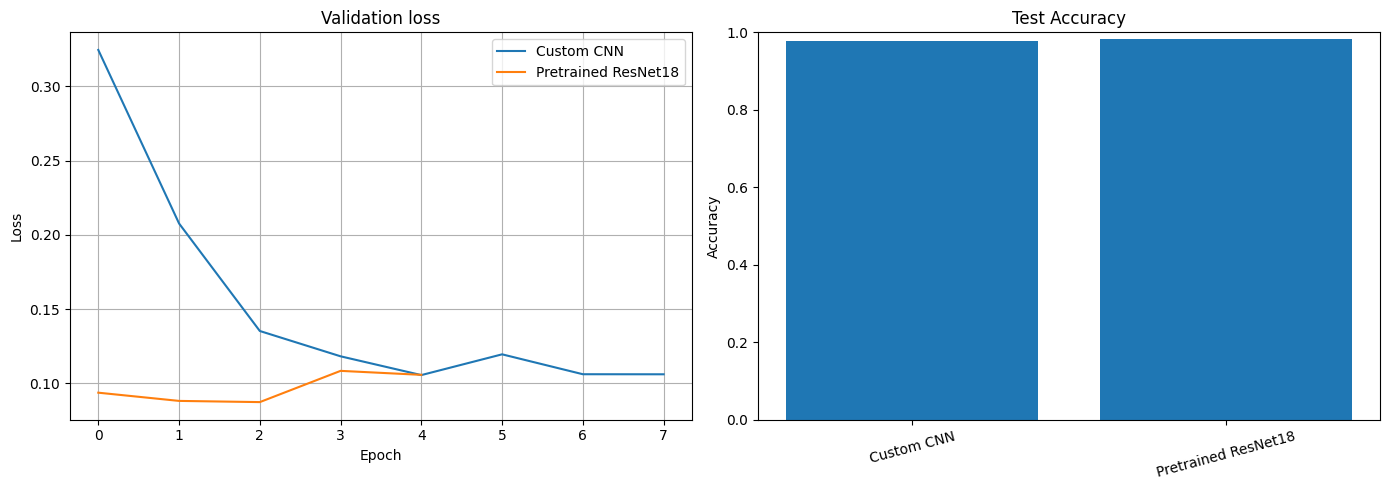

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    cnn_history["val_loss"],
    label="Custom CNN"
)
axes[0].plot(
    resnet_history["val_loss"],
    label="Pretrained ResNet18"
)
axes[0].set_title("Validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid()

axes[1].bar(
    image_model_results["Model"],
    image_model_results["Test Accuracy"]
)
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Accuracy")
axes[1].set_title("Test Accuracy")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

## 2.6. Вплив обсягу тренувальних даних

Щоб оцінити вплив кількості даних, навчимо таку саму просту CNN лише на 25% train-вибірки та порівняємо її з моделлю, навченою на повному train.

In [31]:
small_train_idx, _ = train_test_split(
    train_idx,
    train_size=0.25,
    random_state=RANDOM_STATE,
    stratify=labels[train_idx]
)

small_cnn_train_ds = MalwareImageDataset(
    image_paths,
    labels,
    small_train_idx,
    cnn_transform
)

small_cnn_train_loader = DataLoader(
    small_cnn_train_ds,
    batch_size=BATCH_SIZE_IMAGE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

small_cnn = SimpleCNN(len(classes)).to(device)

small_history, small_train_time = train_image_model(
    small_cnn,
    small_cnn_train_loader,
    cnn_val_loader,
    epochs=CNN_EPOCHS,
    lr=1e-3
)

small_y_true, small_y_pred = predict_loader(
    small_cnn,
    cnn_test_loader
)

small_accuracy = accuracy_score(
    small_y_true,
    small_y_pred
)

data_volume_results = pd.DataFrame({
    "Train data": ["25%", "100%"],
    "Samples": [len(small_train_idx), len(train_idx)],
    "Test Accuracy": [small_accuracy, cnn_accuracy]
})

data_volume_results

Epoch 01/8 | train loss=1.2016, val loss=0.8696 | train acc=0.5688, val acc=0.6416
Epoch 02/8 | train loss=0.6714, val loss=0.4780 | train acc=0.7834, val acc=0.8374
Epoch 03/8 | train loss=0.4415, val loss=0.4101 | train acc=0.8424, val acc=0.8701
Epoch 04/8 | train loss=0.3618, val loss=0.3439 | train acc=0.8704, val acc=0.8858
Epoch 05/8 | train loss=0.3103, val loss=0.3005 | train acc=0.8888, val acc=0.9081
Epoch 06/8 | train loss=0.2719, val loss=0.2840 | train acc=0.9077, val acc=0.8988
Epoch 07/8 | train loss=0.2275, val loss=0.2182 | train acc=0.9256, val acc=0.9441
Epoch 08/8 | train loss=0.2005, val loss=0.2024 | train acc=0.9391, val acc=0.9465


,Train data,Samples,Test Accuracy
0,25%,3859,0.954367
1,100%,15438,0.977637


### Висновок до частини 2

Власна CNN після 8 епох показала 98.01% accuracy на test-вибірці. Pretrained ResNet18 після 5 епох отримала трохи кращий результат - 98.22%.

ResNet18 також навчалася трохи швидше: приблизно 5.88 хв проти 6.39 хв для власної CNN, хоча кількість епох була різною. На learning curves ResNet18 вже на перших епохах має високу validation accuracy, тобто pretrained ознаки допомагають швидше отримати хороший результат.

У власної CNN validation loss перестала помітно покращуватись приблизно після 5–7 епох, а train loss продовжувала зменшуватись. У ResNet18 найменша validation loss була приблизно на 3-й епосі, після чого вона трохи зросла. В обох випадках наприкінці видно слабкі ознаки перенавчання.

Експеримент з обсягом даних показав помітну різницю: при використанні лише 25% train-вибірки CNN отримала 94.98%, а на повній train-вибірці - 98.01%. Отже, збільшення кількості навчальних даних покращило якість приблизно на 3 відсоткові пункти.

# 3. Нейронні мережі для класифікації текстів

Використовуємо той самий Phishing Email Dataset, що і в 2 лабі.

Задача:
- 0 - Legitimate
- 1 - Phishing

Виконаємо:
- токенізацію;
- побудову словника;
- перетворення токенів у індекси;
- padding / truncation;
- GRU з випадковими embeddings;
- GRU з pretrained GloVe embeddings.

In [32]:
PHISH_LOCAL = Path("phishing_email_sample_10000.csv")
PHISH_URL = "https://raw.githubusercontent.com/maksymenkokyrylofb61mp/IAD-Lab2-CLaMP/main/phishing_email_sample_10000.csv"

if PHISH_LOCAL.exists():
    text_df = pd.read_csv(PHISH_LOCAL)
else:
    text_df = pd.read_csv(PHISH_URL)

text_df = text_df.dropna(
    subset=["text_combined", "label"]
).reset_index(drop=True)

print("Розмір:", text_df.shape)
print(text_df["label"].value_counts())

Розмір: (10000, 2)
label
1    5000
0    5000
Name: count, dtype: int64


## 3.1. Train / validation / test

Дані поділено на train, validation і test. Словник будується лише на train-текстах, щоб інформація з validation і test не впливала на підготовку моделі.

In [33]:
text_trainval, text_test = train_test_split(
    text_df,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=text_df["label"]
)

text_train, text_val = train_test_split(
    text_trainval,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=text_trainval["label"]
)

print("Train:", len(text_train))
print("Validation:", len(text_val))
print("Test:", len(text_test))

Train: 6400
Validation: 1600
Test: 2000


## 3.2. Токенізація, vocabulary, індекси та padding

Використаємо просту regex-токенізацію англомовного тексту.

In [34]:
TOKEN_PATTERN = re.compile(r"[a-z]+")

def tokenize(text):
    return TOKEN_PATTERN.findall(str(text).lower())

MAX_VOCAB_SIZE = 20000
MAX_LEN = 200

counter = Counter()

for text in text_train["text_combined"]:
    counter.update(tokenize(text))

most_common_words = counter.most_common(
    MAX_VOCAB_SIZE - 2
)

word_to_idx = {
    "<PAD>": 0,
    "<UNK>": 1
}

for word, _ in most_common_words:
    word_to_idx[word] = len(word_to_idx)

idx_to_word = {
    idx: word
    for word, idx in word_to_idx.items()
}

VOCAB_SIZE = len(word_to_idx)

print("Vocabulary size:", VOCAB_SIZE)

Vocabulary size: 20000


In [35]:
def encode_text(text):
    tokens = tokenize(text)

    ids = [
        word_to_idx.get(token, word_to_idx["<UNK>"])
        for token in tokens[:MAX_LEN]
    ]

    if len(ids) < MAX_LEN:
        ids += [word_to_idx["<PAD>"]] * (
            MAX_LEN - len(ids)
        )

    return ids

class EmailSequenceDataset(Dataset):
    def __init__(self, dataframe):
        self.texts = dataframe["text_combined"].tolist()
        self.labels = dataframe["label"].astype(int).tolist()

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        encoded = encode_text(self.texts[idx])

        return (
            torch.tensor(encoded, dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.long)
        )

text_train_ds = EmailSequenceDataset(text_train)
text_val_ds = EmailSequenceDataset(text_val)
text_test_ds = EmailSequenceDataset(text_test)

TEXT_BATCH_SIZE = 64

text_train_loader = DataLoader(
    text_train_ds,
    batch_size=TEXT_BATCH_SIZE,
    shuffle=True
)
text_val_loader = DataLoader(
    text_val_ds,
    batch_size=TEXT_BATCH_SIZE,
    shuffle=False
)
text_test_loader = DataLoader(
    text_test_ds,
    batch_size=TEXT_BATCH_SIZE,
    shuffle=False
)

## 3.3. GRU із випадково ініціалізованими Embedding

In [36]:
class GRUTextClassifier(nn.Module):
    def __init__(
        self,
        vocab_size,
        embedding_dim,
        hidden_dim,
        num_classes=2,
        embedding_weights=None
    ):
        super().__init__()

        self.embedding = nn.Embedding(
            vocab_size,
            embedding_dim,
            padding_idx=0
        )

        if embedding_weights is not None:
            self.embedding.weight.data.copy_(
                embedding_weights
            )

        self.gru = nn.GRU(
            input_size=embedding_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )

        self.dropout = nn.Dropout(0.30)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        # Реальна довжина кожної послідовності без PAD
        lengths = (x != 0).sum(dim=1).clamp(min=1).cpu()

        embedded = self.embedding(x)

        packed = pack_padded_sequence(
            embedded,
            lengths,
            batch_first=True,
            enforce_sorted=False
        )

        _, hidden = self.gru(packed)

        hidden = hidden[-1]
        hidden = self.dropout(hidden)

        return self.fc(hidden)

In [37]:
def train_sequence_model(
    model,
    train_loader,
    val_loader,
    epochs,
    lr=1e-3
):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=lr
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    best_state = None
    best_val_loss = float("inf")

    start = time.perf_counter()

    for epoch in range(1, epochs + 1):
        train_loss, train_acc = run_epoch_classification(
            model,
            train_loader,
            criterion,
            optimizer
        )

        val_loss, val_acc = run_epoch_classification(
            model,
            val_loader,
            criterion
        )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(
                model.state_dict()
            )

        print(
            f"Epoch {epoch:02d}/{epochs} | "
            f"train loss={train_loss:.4f}, "
            f"val loss={val_loss:.4f} | "
            f"train acc={train_acc:.4f}, "
            f"val acc={val_acc:.4f}"
        )

    elapsed = time.perf_counter() - start

    model.load_state_dict(best_state)

    return history, elapsed

In [38]:
EMBED_DIM = 100
HIDDEN_DIM = 128
TEXT_EPOCHS = 8

random_gru = GRUTextClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM
).to(device)

random_history, random_train_time = train_sequence_model(
    random_gru,
    text_train_loader,
    text_val_loader,
    epochs=TEXT_EPOCHS,
    lr=1e-3
)

Epoch 01/8 | train loss=0.4891, val loss=0.3532 | train acc=0.7516, val acc=0.8781
Epoch 02/8 | train loss=0.2322, val loss=0.2340 | train acc=0.9169, val acc=0.9156
Epoch 03/8 | train loss=0.1256, val loss=0.2010 | train acc=0.9578, val acc=0.9250
Epoch 04/8 | train loss=0.1130, val loss=0.1836 | train acc=0.9614, val acc=0.9413
Epoch 05/8 | train loss=0.0566, val loss=0.1751 | train acc=0.9828, val acc=0.9469
Epoch 06/8 | train loss=0.0365, val loss=0.1985 | train acc=0.9902, val acc=0.9363
Epoch 07/8 | train loss=0.0316, val loss=0.2166 | train acc=0.9920, val acc=0.9281
Epoch 08/8 | train loss=0.0200, val loss=0.2001 | train acc=0.9948, val acc=0.9456


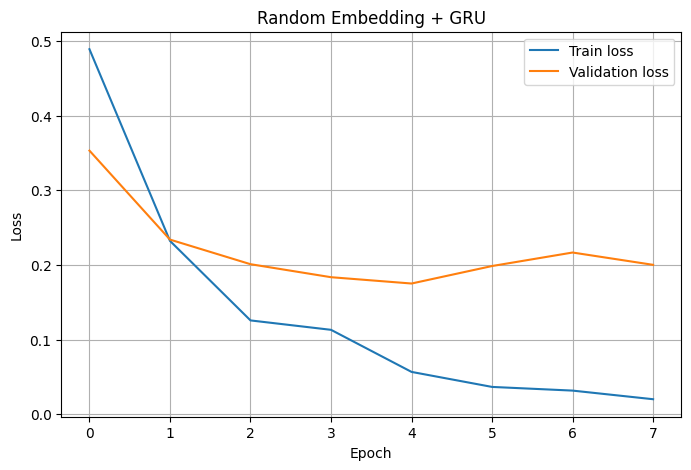

In [39]:
plt.figure(figsize=(8, 5))
plt.plot(
    random_history["train_loss"],
    label="Train loss"
)
plt.plot(
    random_history["val_loss"],
    label="Validation loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Random Embedding + GRU")
plt.legend()
plt.grid()
plt.show()

In [40]:
random_y_true, random_y_pred = predict_loader(
    random_gru,
    text_test_loader
)

random_accuracy = accuracy_score(
    random_y_true,
    random_y_pred
)

random_f1 = f1_score(
    random_y_true,
    random_y_pred
)

print(f"Random Embedding GRU Accuracy: {random_accuracy:.4f}")
print(f"Random Embedding GRU F1: {random_f1:.4f}\n")

print(
    classification_report(
        random_y_true,
        random_y_pred,
        target_names=["Legitimate", "Phishing"]
    )
)

Random Embedding GRU Accuracy: 0.9425
Random Embedding GRU F1: 0.9431

              precision    recall  f1-score   support

  Legitimate       0.95      0.93      0.94      1000
    Phishing       0.93      0.95      0.94      1000

    accuracy                           0.94      2000
   macro avg       0.94      0.94      0.94      2000
weighted avg       0.94      0.94      0.94      2000



## 3.4. GRU з pretrained GloVe embeddings

Використаємо glove-wiki-gigaword-100 через gensim.

Для слів, які присутні у GloVe, embedding vector береться з pretrained моделі.  
Для невідомих слів використовуються невеликі випадкові значення.

In [41]:
import gensim.downloader as api

print("Завантаження GloVe...")
glove = api.load("glove-wiki-gigaword-100")

print("GloVe loaded.")

Завантаження GloVe...
[==================================================] 100.0% 128.1/128.1MB downloaded
GloVe loaded.


In [42]:
embedding_matrix = np.random.normal(
    0,
    0.05,
    size=(VOCAB_SIZE, EMBED_DIM)
).astype(np.float32)

# PAD = нульовий вектор
embedding_matrix[0] = np.zeros(
    EMBED_DIM,
    dtype=np.float32
)

found = 0

for word, idx in word_to_idx.items():
    if word in ("<PAD>", "<UNK>"):
        continue

    if word in glove:
        embedding_matrix[idx] = glove[word]
        found += 1

coverage = found / max(VOCAB_SIZE - 2, 1)

print("Words found in GloVe:", found)
print(f"Vocabulary coverage: {coverage:.2%}")

embedding_tensor = torch.tensor(
    embedding_matrix,
    dtype=torch.float32
)

Words found in GloVe: 16614
Vocabulary coverage: 83.08%


In [43]:
glove_gru = GRUTextClassifier(
    vocab_size=VOCAB_SIZE,
    embedding_dim=EMBED_DIM,
    hidden_dim=HIDDEN_DIM,
    embedding_weights=embedding_tensor
).to(device)

# Embeddings можна донавчати разом із моделлю
glove_gru.embedding.weight.requires_grad = True

glove_history, glove_train_time = train_sequence_model(
    glove_gru,
    text_train_loader,
    text_val_loader,
    epochs=TEXT_EPOCHS,
    lr=5e-4
)

Epoch 01/8 | train loss=0.4711, val loss=0.2416 | train acc=0.7817, val acc=0.9169
Epoch 02/8 | train loss=0.1783, val loss=0.1846 | train acc=0.9397, val acc=0.9387
Epoch 03/8 | train loss=0.1243, val loss=0.7985 | train acc=0.9647, val acc=0.7444
Epoch 04/8 | train loss=0.1768, val loss=0.1643 | train acc=0.9400, val acc=0.9450
Epoch 05/8 | train loss=0.0726, val loss=0.1669 | train acc=0.9775, val acc=0.9513
Epoch 06/8 | train loss=0.0446, val loss=0.1523 | train acc=0.9883, val acc=0.9544
Epoch 07/8 | train loss=0.0327, val loss=0.1639 | train acc=0.9922, val acc=0.9563
Epoch 08/8 | train loss=0.0292, val loss=0.1531 | train acc=0.9922, val acc=0.9587


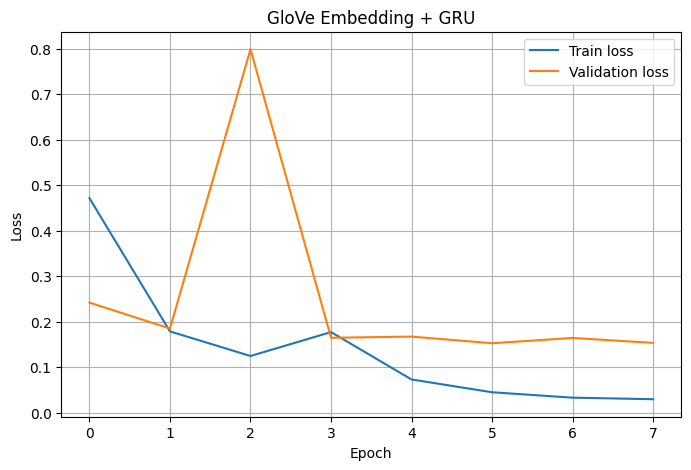

In [44]:
plt.figure(figsize=(8, 5))
plt.plot(
    glove_history["train_loss"],
    label="Train loss"
)
plt.plot(
    glove_history["val_loss"],
    label="Validation loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("GloVe Embedding + GRU")
plt.legend()
plt.grid()
plt.show()

In [45]:
glove_y_true, glove_y_pred = predict_loader(
    glove_gru,
    text_test_loader
)

glove_accuracy = accuracy_score(
    glove_y_true,
    glove_y_pred
)

glove_f1 = f1_score(
    glove_y_true,
    glove_y_pred
)

print(f"GloVe GRU Accuracy: {glove_accuracy:.4f}")
print(f"GloVe GRU F1: {glove_f1:.4f}\n")

print(
    classification_report(
        glove_y_true,
        glove_y_pred,
        target_names=["Legitimate", "Phishing"]
    )
)

GloVe GRU Accuracy: 0.9590
GloVe GRU F1: 0.9594

              precision    recall  f1-score   support

  Legitimate       0.97      0.95      0.96      1000
    Phishing       0.95      0.97      0.96      1000

    accuracy                           0.96      2000
   macro avg       0.96      0.96      0.96      2000
weighted avg       0.96      0.96      0.96      2000



In [46]:
text_results = pd.DataFrame({
    "Model": [
        "Random Embedding + GRU",
        "GloVe + GRU"
    ],
    "Accuracy": [
        random_accuracy,
        glove_accuracy
    ],
    "F1": [
        random_f1,
        glove_f1
    ],
    "Training time, s": [
        random_train_time,
        glove_train_time
    ]
})

text_results

,Model,Accuracy,F1,"Training time, s"
0,Random Embedding + GRU,0.9425,0.943097,19.082080
1,GloVe + GRU,0.9590,0.959366,18.734635


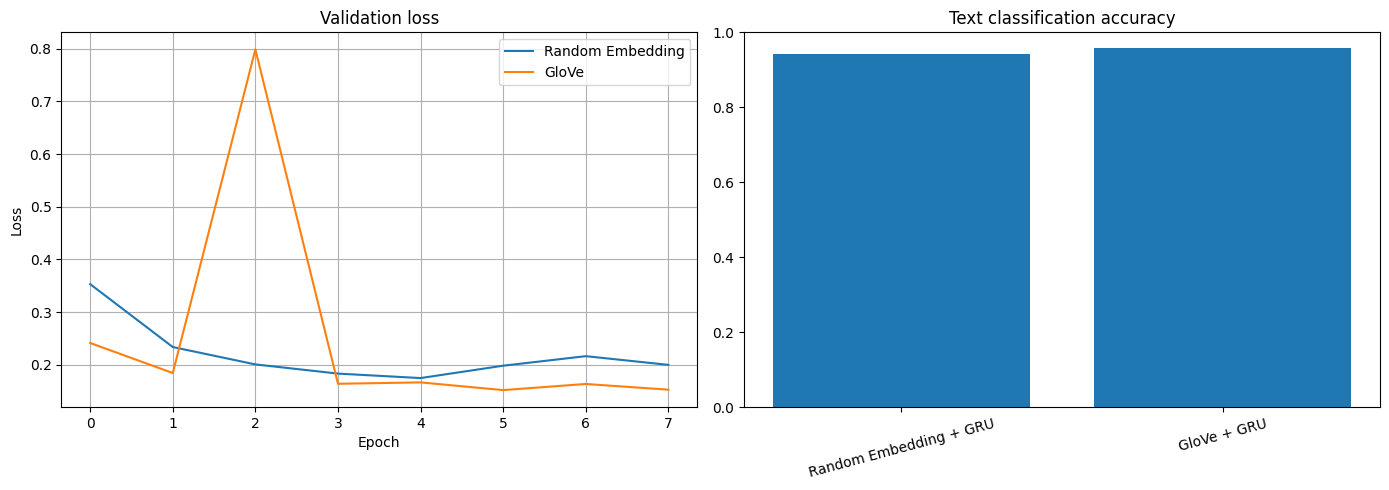

In [47]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(
    random_history["val_loss"],
    label="Random Embedding"
)
axes[0].plot(
    glove_history["val_loss"],
    label="GloVe"
)
axes[0].set_title("Validation loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid()

axes[1].bar(
    text_results["Model"],
    text_results["Accuracy"]
)
axes[1].set_ylim(0, 1)
axes[1].set_title("Text classification accuracy")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

### Висновок до частини 3

GRU з випадково ініціалізованим Embedding показала 94.25% accuracy та F1 = 0.9431. Найкраща validation loss для цієї моделі була приблизно на 5-й епосі; далі train loss продовжувала зменшуватись, а validation loss зросла, тому видно ознаки перенавчання.

Для GloVe вдалося знайти pretrained вектори для 83.08% слів словника. Модель GloVe + GRU показала кращий результат: 95.90% accuracy та F1 = 0.9594.

Час навчання був близьким: приблизно 19.08 с для випадкових embedding і 17.94 с для GloVe. На 3-й епосі GloVe-модель мала різкий стрибок validation loss, але на наступних епохах відновилась і в результаті показала найкращу якість.

Отже, у цьому експерименті pretrained GloVe embeddings дали приріст accuracy приблизно на 1.65 відсоткового пункту та покращили F1.

# Загальний висновок

У роботі було перевірено нейронні мережі на трьох типах даних.

1. Табличні дані (CLaMP). MLP отримала 95.94% accuracy. Вона поступилась найкращій класичній моделі з Lab 1 - Random Forest (98.90%). Після приблизно 17-ї епохи з'явилися слабкі ознаки перенавчання.

2. Зображення malware/benign. Власна CNN отримала 98.01%, а pretrained ResNet18 - 98.22%. ResNet18 досягла високої якості за меншу кількість епох. Зменшення train-вибірки до 25% знизило accuracy CNN до 94.98%, тому обсяг навчальних даних помітно вплинув на результат.

3. Phishing email. GRU з випадковими embedding отримала 94.25% accuracy, а GRU з GloVe - 95.90%. GloVe покрила 83.08% словника та дала кращі Accuracy і F1 при близькому часі навчання.

За отриманими результатами pretrained підходи дали невелику, але помітну перевагу для зображень і текстів. Для невеликого табличного датасета класичний Random Forest залишився кращим за MLP.